In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd drive/MyDrive/4.KNearestNeigbors
%ls

In [2]:
import pandas

In [ ]:
df = pandas.read_csv("Customers.csv")

print(df)

In [ ]:
d_age = {'young': 0, 'middle': 1, 'old': 2}
d_income = {'high': 0, 'medium': 1, 'low': 2}
d_student = {'no': 0, 'yes': 1}
d_credit_rating = {'fair': 0, 'excellent': 1}
d_buy_computer = {'no': 0, 'yes': 1}

df['Age'] = df['Age'].map(d_age)
df['Income'] = df['Income'].map(d_income)
df['Student'] = df['Student'].map(d_student)
df['Credit_rating'] = df['Credit_rating'].map(d_credit_rating)
df['Buy_computer'] = df['Buy_computer'].map(d_buy_computer)

print(df)

In [5]:
features = ['Age', 'Income', 'Student', 'Credit_rating']

data = df[features]
classes = df['Buy_computer']

In [ ]:
print(data)
print('\n\n')
print(classes)

In [7]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
knn = KNeighborsClassifier(n_neighbors=1)

knn.fit(data, classes)

In [ ]:
df_validation = pandas.read_csv("validation_set.csv")

print(df_validation)

In [10]:
df_validation['Age'] = df_validation['Age'].map(d_age)
df_validation['Income'] = df_validation['Income'].map(d_income)
df_validation['Student'] = df_validation['Student'].map(d_student)
df_validation['Credit_rating'] = df_validation['Credit_rating'].map(d_credit_rating)

df_validation['Buy_computer'] = df_validation['Buy_computer'].map(d_buy_computer)

test_df = df_validation[features]

print(test_df)

    Age  Income  Student  Credit_rating
0     2       2        1              0
1     2       0        0              0
2     0       2        0              1
3     1       2        0              0
4     2       2        1              1
5     0       0        1              1
6     0       0        0              0
7     0       2        1              0
8     1       0        1              1
9     0       0        0              0
10    2       2        0              1


In [31]:
predicted_classes = list(knn.predict(test_df))

print(predicted_classes)

[1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0]


In [25]:
actual_classes = df_validation['Buy_computer'].values.tolist()

print(actual_classes)

[1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0]


In [13]:
from sklearn import metrics

confusion_matrix = metrics.confusion_matrix(actual_classes, predicted_classes)

In [14]:
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [False, True])

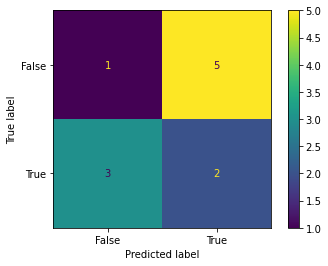

In [15]:
import matplotlib.pyplot as plt
cm_display.plot()
plt.show()

In [32]:
Accuracy = metrics.accuracy_score(actual_classes, predicted_classes)
print(Accuracy)

0.2727272727272727


In [27]:
Precision = metrics.precision_score(actual_classes, predicted_classes)
print(Precision)

0.25


In [28]:
Sensitivity_recall = metrics.recall_score(actual_classes, predicted_classes)
print(Sensitivity_recall)

0.4


In [29]:
Specificity = metrics.recall_score(actual_classes, predicted_classes, pos_label=0)
print(Specificity)

0.0


In [20]:
F1_score = metrics.f1_score(actual_classes, predicted_classes)
print(F1_score)

0.3333333333333333


In [21]:
print({"Accuracy":Accuracy,"Precision":Precision,"Sensitivity_recall":Sensitivity_recall,"Specificity":Specificity,"F1_score":F1_score})

{'Accuracy': 0.2727272727272727, 'Precision': 0.2857142857142857, 'Sensitivity_recall': 0.4, 'Specificity': 0.16666666666666666, 'F1_score': 0.3333333333333333}


In [ ]:
data = df.values.tolist()